### **Importing modBHJet**

In [1]:
from pathlib import Path
import sys

ROOT = Path("/Users/ruby/Desktop/University/phd/bhjet_mod/modBHJet")
sys.path.insert(0, str(ROOT / "python"))

import numpy as np
import matplotlib.pyplot as plt

import bhjet
from bhjet import BLJet, BHJet
# print("Using bhjet from:", bhjet.__file__)

erg2eV = 6.242e+11 # 1erg in eV
eV2erg = 1/erg2eV

#### **Test that Help Functions Work** (peek into cpp code)

In [2]:
help(bhjet.BHJet.compton_threshold)

Help on property:

    (self) -> float



In [3]:
#wow this actually works
help(bhjet.RadiationZone.get_observed_photon_energy_grid_electron_cyclosyn)

Help on nb_method in module bhjet.bhjet:

get_observed_photon_energy_grid_electron_cyclosyn(...)
    get_observed_photon_energy_grid_electron_cyclosyn(self) -> list[float]

    / Observed photon energy grid for cyclo-synchrotron emission



#### **How to set up vanilla BHJet**

Need to start by setting up the dynamic profile of the jet that we want to reproduce. In this case it's the magnetic driven jet, which is called BLJet, which we'll name mag_jet_dyn. These parameters first set up the jet properties, which will set up the jet profile (named vanilla_bhjet). 

In [4]:
#with hand set parameters: 
mag_jet_dyn = BLJet(
    mass_bh=6e8,
    jet_power_eddington=1e-3,
    z_jet_launching=2,
    r_initial=5,
    z_end_of_acceleration=1e1,
    z_dissipation=120,
    z_max_calculation=1e6,
    sigma_final=1,
    gamma_final=3,
    electron_temperature_jet_base=1e2,
    fraction_nonthermal_electrons=0.1,
    index_injected_electrons=1.8,
    dlgz=0.1,
    verbosity_level=1,
    cutoff_type=0, 
    f_shock_heating_factor = 2,
    f_particle_dissipation_index = 0,

)

In [5]:
#with hand set parameters: 
test_dyn = BLJet(
    mass_bh=6e8,
    jet_power_eddington=1e-3,
    z_jet_launching=2,
    r_initial=5,
    z_end_of_acceleration=1e1,
    z_dissipation=120,
    z_max_calculation=1e6,
    sigma_final=1,
    gamma_final=3,
    electron_temperature_jet_base=1e2,
    fraction_nonthermal_electrons=0.1,
    index_injected_electrons=1.8,
    dlgz=0.1,
    verbosity_level=1,
    cutoff_type=0, 
    f_shock_heating_factor = 2,
    f_particle_dissipation_index = 6,

)

In [6]:
bhjet = BHJet(
    theta_obs=17,
    distance=16e3,     # kpc
    redshift=0.00428,
    include_counterjet=True,
    compton_threshold=1e-5,
    profile_time=True,
    verbosity_level=1,
)

test_bhjet = BHJet(
    theta_obs=17,
    distance=16e3,     # kpc
    redshift=0.00428,
    include_counterjet=True,
    compton_threshold=1e-5,
    profile_time=True,
    verbosity_level=1,
)
bhjet.init_jet_dynamics(mag_jet_dyn)
test_bhjet.init_jet_dynamics(test_dyn)

In [7]:
erg2eV = 6.242e+11 # 1erg in eV
eV2erg = 1/erg2eV

E_eV = np.logspace(-8, 19, 200) #need to provide an energy grid for the model to calculate over 
bhjet.compute_full_jet(photon_energy_grid=E_eV * eV2erg) 
test_bhjet.compute_full_jet(photon_energy_grid=E_eV * eV2erg)
flux = bhjet.get_observed_photon_flux_total() #E dN/dE

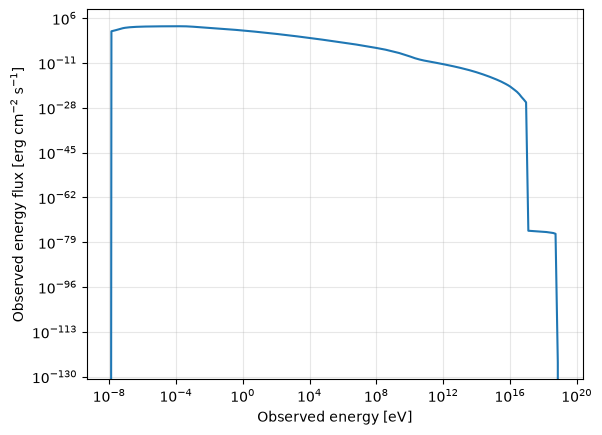

In [8]:
plt.loglog(E_eV, flux)
plt.xlabel("Observed energy [eV]")
plt.ylabel(r"Observed energy flux [erg cm$^{-2}$ s$^{-1}$]")
plt.grid(alpha=0.3)
# plt.ylim(1e-15, 1e-9)
plt.show()

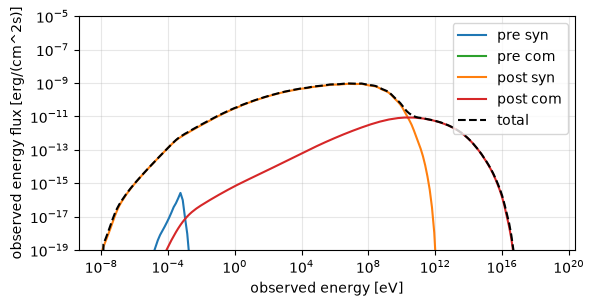

In [9]:
fig, ax = plt.subplots()
# bhjet.set_target_black_body_luminosity("starlight", 1e45)

# ax.loglog(bb_starlight.get_observed_energy()*erg2eV, bb_starlight.get_observed_energy_flux(), label=bb_starlight.name, color="tab:purple")
# Ebb = bhjet.get_observed_photon_energy_grid_black_body("starlight")
# ax.loglog(Ebb*erg2eV, Ebb*bhjet.get_observed_photon_flux_black_body("starlight"), c="tab:purple", label="starlight")

ax.loglog(E_eV, E_eV*eV2erg*bhjet.get_observed_photon_integrated_flux_electron_cyclosyn(
    0, mag_jet_dyn.z_dissipation*mag_jet_dyn.r_g), c="tab:blue", label="pre syn")
ax.loglog(E_eV, E_eV*eV2erg*bhjet.get_observed_photon_integrated_flux_electron_compton(
    0, mag_jet_dyn.z_dissipation*mag_jet_dyn.r_g), c="tab:green", label="pre com")
ax.loglog(E_eV, E_eV*eV2erg*bhjet.get_observed_photon_integrated_flux_electron_cyclosyn(
    mag_jet_dyn.z_dissipation*mag_jet_dyn.r_g, mag_jet_dyn.z_max_calculation*mag_jet_dyn.r_g), c="tab:orange", label="post syn")
ax.loglog(E_eV, E_eV*eV2erg*bhjet.get_observed_photon_integrated_flux_electron_compton(
    mag_jet_dyn.z_dissipation*mag_jet_dyn.r_g, mag_jet_dyn.z_max_calculation*mag_jet_dyn.r_g), c="tab:red", label="post com")
ax.loglog(E_eV, E_eV*eV2erg*bhjet.get_observed_photon_flux_total(), c="k", label="total", ls="--")

ax.legend()
ax.set_xlabel(r"observed energy [eV]")
ax.set_ylabel(r"observed energy flux [erg/(cm^2s)]")
ax.set_ylim(1e-19, 1e-5)
ax.set_aspect("equal")
ax.grid(alpha=0.3)

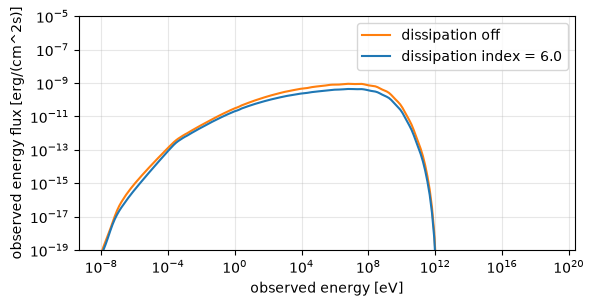

In [10]:
fig, ax = plt.subplots()

ax.loglog(E_eV, E_eV*eV2erg*bhjet.get_observed_photon_integrated_flux_electron_cyclosyn(
    mag_jet_dyn.z_dissipation*mag_jet_dyn.r_g, mag_jet_dyn.z_max_calculation*mag_jet_dyn.r_g), c="tab:orange", label="dissipation off")

ax.loglog(E_eV, E_eV*eV2erg*test_bhjet.get_observed_photon_integrated_flux_electron_cyclosyn(
    test_dyn.z_dissipation*test_dyn.r_g, test_dyn.z_max_calculation*test_dyn.r_g), c="tab:blue", label=f"dissipation index = {test_dyn.f_particle_dissipation_index}")

ax.legend()
ax.set_xlabel(r"observed energy [eV]")
ax.set_ylabel(r"observed energy flux [erg/(cm^2s)]")
ax.set_ylim(1e-19, 1e-5)
ax.set_aspect("equal")
ax.grid(alpha=0.3)

#### How to change the shape of the cutoff function: 

In [11]:
energy = np.logspace(-8, 19, 200).tolist()
models = {}

for cutoff_type in [0, 1, 2]:
    dyn_i = BLJet(cutoff_type=cutoff_type)
    jet_i = BHJet()
    jet_i.init_jet_dynamics(dyn_i)
    jet_i.compute_full_jet(energy)
    models[cutoff_type] = np.asarray(jet_i.get_observed_photon_flux_total())

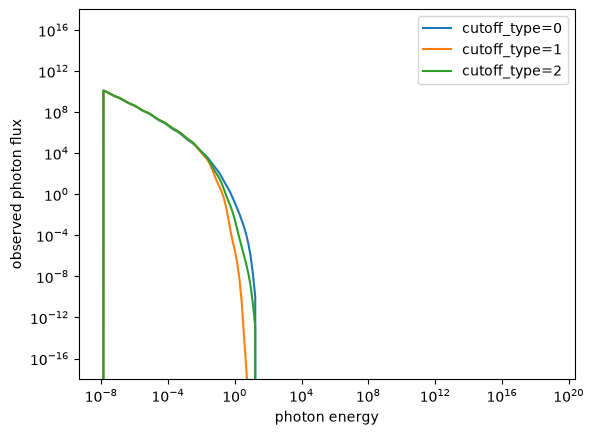

In [12]:
plt.figure()
for cutoff_type, flux in models.items():
    plt.loglog(energy, flux, label=f"cutoff_type={cutoff_type}")

plt.xlabel("photon energy")
plt.ylabel("observed photon flux")
plt.ylim(1e-18, 1e18)
plt.legend()
plt.show()

### Compare magnetic, adiabatic, and isothermal jet profiles
Shared base inputs; the magnetic model uses its own acceleration parameters. Run after restarting the kernel with the rebuilt AdiJet bindings.

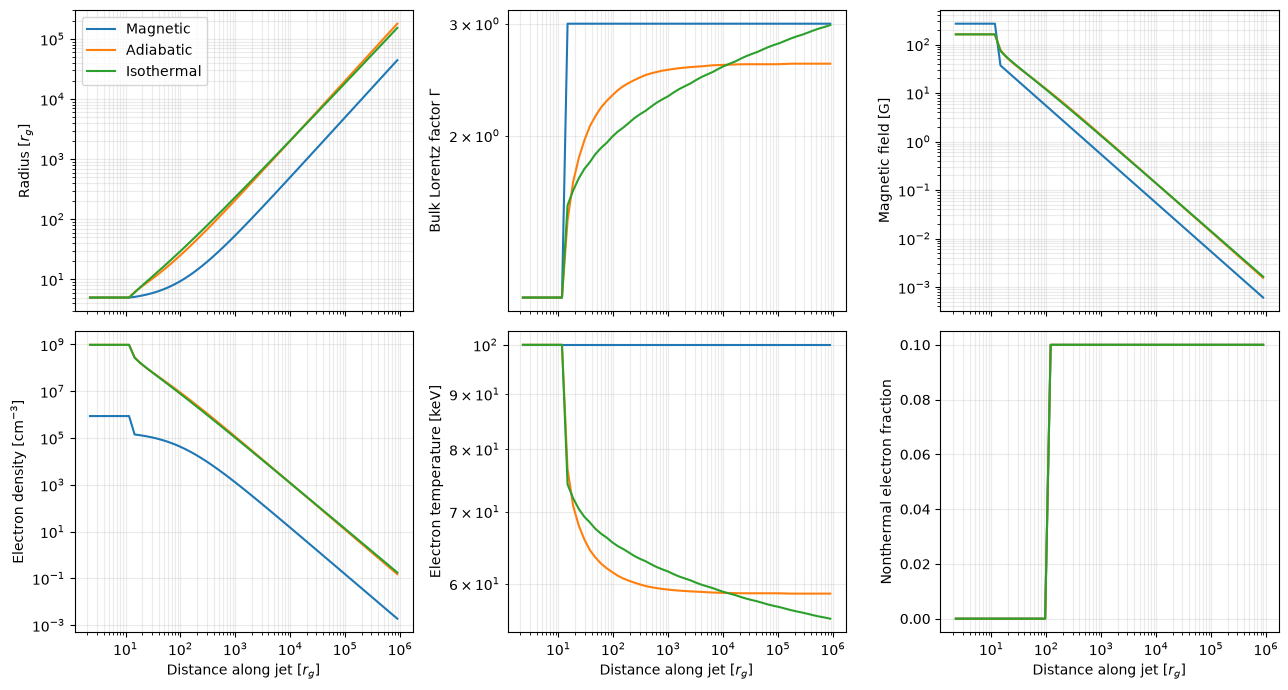

In [13]:
# Compare dynamics only: no radiation calculation is needed.
import numpy as np
import matplotlib.pyplot as plt
from bhjet import BLJet, AdiJet, IsoJet

# Shared inputs; each prescription keeps its own acceleration physics.
profile_parameters = dict(
    mass_bh=6e8,
    jet_power_eddington=1e-3,
    z_jet_launching=2,
    r_initial=5,
    z_dissipation=120,
    z_max_calculation=1e6,
    electron_temperature_jet_base=100,
    plasma_beta_jet_base=1,
    dlgz=0.1,
    verbosity_level=0,
)
profile_models = {
    "Magnetic": BLJet(**profile_parameters, z_end_of_acceleration=10,
                       gamma_final=3, sigma_final=1),
    "Adiabatic": AdiJet(**profile_parameters),
    "Isothermal": IsoJet(**profile_parameters),
}

profile_panels = [
    ("get_radius_grid", r"Radius [$r_g$]", True),
    ("get_gamma_grid", r"Bulk Lorentz factor $\Gamma$", False),
    ("get_magnetic_field_grid", "Magnetic field [G]", False),
    ("get_electron_density_grid", r"Electron density [cm$^{-3}$]", False),
    ("get_electron_temperature_grid", "Electron temperature [keV]", False),
    ("get_fraction_nonthermal_electrons_grid", "Nonthermal electron fraction", False),
]
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True)
for label, dynamics in profile_models.items():
    dynamics.compute_jet_dynamics()
    z_rg = np.asarray(dynamics.get_z_center_grid()) / dynamics.r_g
    for ax, (getter, ylabel, scale_radius) in zip(axes.flat, profile_panels):
        values = np.asarray(getattr(dynamics, getter)())
        assert values.shape == z_rg.shape and np.all(np.isfinite(values)), (label, getter)
        if scale_radius:
            values = values / dynamics.r_g
        ax.plot(z_rg, values, label=label)
        ax.set_xscale("log")
        if getter != "get_fraction_nonthermal_electrons_grid":
            ax.set_yscale("log")
        ax.set_ylabel(ylabel)
        ax.grid(True, which="both", alpha=0.25)
for ax in axes[-1]:
    ax.set_xlabel(r"Distance along jet [$r_g$]")
axes[0, 0].legend()
fig.tight_layout()
plt.show()
